# Laboratorium 4 - Obsługa długich sekwencji: SimpleRNN, LSTM, GRU, Conv1D

## 1. Instalacja i import

In [1]:
!pip -q install torch numpy matplotlib

In [2]:
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

ZIARNO = 0
torch.manual_seed(ZIARNO)
np.random.seed(ZIARNO)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch:', torch.__version__)
print('Urządzenie:', DEVICE)

PyTorch: 2.11.0+cpu
Urządzenie: cpu


## 2. Generator danych z opóźnionymi znacznikami

In [3]:
OPOZNIENIE = 8


def generuj(N, L, rng):
    v = rng.random((N, L)).astype(np.float32)
    m = np.zeros((N, L), np.float32)
    y = np.zeros((N, 1), np.float32)
    for i in range(N):
        p = rng.choice(np.arange(OPOZNIENIE, L), 2, replace=False)
        m[i, p] = 1.0
        y[i, 0] = v[i, p - OPOZNIENIE].sum()
    x = np.stack([v, m], axis=2)
    return x, y


def do_tensora(a):
    return torch.tensor(a).to(DEVICE)

## 3. Ręczne sprawdzenie generatora

In [4]:
x1, y1 = generuj(1, 20, np.random.default_rng(ZIARNO))
print('krok  wartość  znacznik')
for t in range(20):
    print(f'{t + 1:4d}  {x1[0, t, 0]:.4f}  {int(x1[0, t, 1]):8d}')

znaczniki = np.where(x1[0, :, 1] == 1)[0] + 1
wskazane = znaczniki - OPOZNIENIE
wartosci = x1[0, wskazane - 1, 0]
print('\nZnaczniki w krokach:', znaczniki.tolist())
print('Wskazane kroki:', wskazane.tolist())
print('Wartości we wskazanych krokach:', [round(float(w), 4) for w in wartosci])
print(f'Suma policzona ręcznie: {wartosci[0]:.4f} + {wartosci[1]:.4f} = {wartosci.sum():.4f}')
print(f'Cel z generatora: {y1[0, 0]:.4f}')

krok  wartość  znacznik
   1  0.6370         0
   2  0.2698         0
   3  0.0410         0
   4  0.0165         0
   5  0.8133         0
   6  0.9128         0
   7  0.6066         0
   8  0.7295         0
   9  0.5436         1
  10  0.9351         0
  11  0.8159         0
  12  0.0027         0
  13  0.8574         1
  14  0.0336         0
  15  0.7297         0
  16  0.1757         0
  17  0.8632         0
  18  0.5415         0
  19  0.2997         0
  20  0.4227         0

Znaczniki w krokach: [9, 13]
Wskazane kroki: [1, 5]
Wartości we wskazanych krokach: [0.637, 0.8133]
Suma policzona ręcznie: 0.6370 + 0.8133 = 1.4502
Cel z generatora: 1.4502


## 4. Modele

In [5]:
class RNNNet(nn.Module):
    def __init__(self, typ, hidden=32):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(2, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


class ConvNet(nn.Module):
    def __init__(self, dylatacje=(1, 2, 4), ch=32, k=3):
        super().__init__()
        warstwy, wej = [], 2
        for d in dylatacje:
            warstwy += [nn.Conv1d(wej, ch, k, stride=1, padding=d * (k - 1) // 2, dilation=d),
                        nn.ReLU()]
            wej = ch
        self.net = nn.Sequential(*warstwy)
        self.fc = nn.Linear(ch, 1)

    def forward(self, x):
        h = self.net(x.transpose(1, 2)).mean(dim=2)
        return self.fc(h)


def licz_parametry(m):
    return sum(p.numel() for p in m.parameters())


def pole_recepcyjne(dylatacje, k=3):
    return 1 + (k - 1) * sum(dylatacje)

## 5. Uczenie i ocena

In [6]:
N_TR, N_TE = 4000, 800
EPOKI, LR, BATCH = 30, 5e-3, 128


def synchronizuj():
    if DEVICE == 'cuda':
        torch.cuda.synchronize()


def trenuj(model, Xtr, Ytr):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    Lf = nn.MSELoss()
    N = len(Xtr)
    synchronizuj()
    t0 = time.perf_counter()
    for ep in range(EPOKI):
        model.train()
        perm = torch.randperm(N)
        for i in range(0, N, BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            Lf(model(Xtr[idx]), Ytr[idx]).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
    synchronizuj()
    return time.perf_counter() - t0


def ocen(model, Xte, Yte):
    model.eval()
    with torch.no_grad():
        pred = model(Xte)
    return nn.functional.mse_loss(pred, Yte).item(), pred.cpu().numpy().ravel()

## 6. Dane dla L = 50 i L = 100 oraz predykcja stała

In [7]:
DLUGOSCI = [50, 100]
dane = {}
for L in DLUGOSCI:
    rng = np.random.default_rng(ZIARNO)
    xtr, ytr = generuj(N_TR, L, rng)
    xte, yte = generuj(N_TE, L, rng)
    stala = float(ytr.mean())
    dane[L] = {
        'Xtr': do_tensora(xtr), 'Ytr': do_tensora(ytr),
        'Xte': do_tensora(xte), 'Yte': do_tensora(yte),
        'xte': xte, 'yte': yte.ravel(),
        'stala': stala, 'mse_stala': float(((yte - stala) ** 2).mean()),
    }
    print(f'L={L}: trening {xtr.shape}, test {xte.shape}, '
          f'średnia celu z treningu = {stala:.4f}, '
          f'test MSE predykcji stałej = {dane[L]["mse_stala"]:.4f}')

L=50: trening (4000, 50, 2), test (800, 50, 2), średnia celu z treningu = 0.9940, test MSE predykcji stałej = 0.1587
L=100: trening (4000, 100, 2), test (800, 100, 2), średnia celu z treningu = 0.9947, test MSE predykcji stałej = 0.1623


## 7. Porównanie czterech modeli

In [8]:
BUDOWA = {
    'SimpleRNN': lambda: RNNNet('RNN'),
    'LSTM': lambda: RNNNet('LSTM'),
    'GRU': lambda: RNNNet('GRU'),
    'Conv1D': lambda: ConvNet((1, 2, 4)),
}

wyniki = {}


def uruchom(nazwa, budowa, L):
    d = dane[L]
    torch.manual_seed(ZIARNO)
    m = budowa()
    czas = trenuj(m, d['Xtr'], d['Ytr'])
    mse, pred = ocen(m, d['Xte'], d['Yte'])
    wyniki[(nazwa, L)] = {'mse': mse, 'czas': czas, 'parametry': licz_parametry(m),
                          'pred': pred}
    print(f'{nazwa:30s} L={L:3d}  test MSE={mse:.4f}  czas={czas:6.1f} s  '
          f'parametry={licz_parametry(m)}')


for L in DLUGOSCI:
    for nazwa, budowa in BUDOWA.items():
        uruchom(nazwa, budowa, L)

SimpleRNN                      L= 50  test MSE=0.1585  czas=   5.8 s  parametry=1185
LSTM                           L= 50  test MSE=0.1589  czas=   9.4 s  parametry=4641
GRU                            L= 50  test MSE=0.1515  czas=  15.9 s  parametry=3489
Conv1D                         L= 50  test MSE=0.1684  czas=   8.5 s  parametry=6465
SimpleRNN                      L=100  test MSE=0.1632  czas=  10.9 s  parametry=1185
LSTM                           L=100  test MSE=0.1625  czas=  18.1 s  parametry=4641
GRU                            L=100  test MSE=0.1613  czas=  30.8 s  parametry=3489
Conv1D                         L=100  test MSE=0.1610  czas=  14.4 s  parametry=6465


## 8. Warianty dla L = 100

In [9]:
WARIANTY = {
    'SimpleRNN, hidden=64': lambda: RNNNet('RNN', hidden=64),
    'Conv1D, dylatacje [1, 1, 1]': lambda: ConvNet((1, 1, 1)),
}
for nazwa, budowa in WARIANTY.items():
    uruchom(nazwa, budowa, 100)

for dyl in [(1, 2, 4), (1, 1, 1)]:
    R = pole_recepcyjne(dyl)
    print(f'dylatacje {list(dyl)}: pole recepcyjne = {R}, '
          f'zasięg od pozycji: ±{(R - 1) // 2}, '
          f'obejmuje znacznik i wartość ({OPOZNIENIE + 1} kolejnych kroków): {R >= OPOZNIENIE + 1}')

SimpleRNN, hidden=64           L=100  test MSE=0.1640  czas=  18.4 s  parametry=4417
Conv1D, dylatacje [1, 1, 1]    L=100  test MSE=0.1609  czas=  13.2 s  parametry=6465
dylatacje [1, 2, 4]: pole recepcyjne = 15, zasięg od pozycji: ±7, obejmuje znacznik i wartość (9 kolejnych kroków): True
dylatacje [1, 1, 1]: pole recepcyjne = 7, zasięg od pozycji: ±3, obejmuje znacznik i wartość (9 kolejnych kroków): False


## 9. Tabela wyników

In [10]:
print(f'{"model":30s} {"L":>4s} {"test MSE":>9s} {"czas [s]":>9s} {"parametry":>10s}')
for L in DLUGOSCI:
    print(f'{"predykcja stała":30s} {L:4d} {dane[L]["mse_stala"]:9.4f} {"-":>9s} {"-":>10s}')
    for nazwa in list(BUDOWA) + (list(WARIANTY) if L == 100 else []):
        w = wyniki[(nazwa, L)]
        print(f'{nazwa:30s} {L:4d} {w["mse"]:9.4f} {w["czas"]:9.1f} {w["parametry"]:10d}')

model                             L  test MSE  czas [s]  parametry
predykcja stała                  50    0.1587         -          -
SimpleRNN                        50    0.1585       5.8       1185
LSTM                             50    0.1589       9.4       4641
GRU                              50    0.1515      15.9       3489
Conv1D                           50    0.1684       8.5       6465
predykcja stała                 100    0.1623         -          -
SimpleRNN                       100    0.1632      10.9       1185
LSTM                            100    0.1625      18.1       4641
GRU                             100    0.1613      30.8       3489
Conv1D                          100    0.1610      14.4       6465
SimpleRNN, hidden=64            100    0.1640      18.4       4417
Conv1D, dylatacje [1, 1, 1]     100    0.1609      13.2       6465


## 10. Test MSE czterech modeli dla L = 50 i L = 100

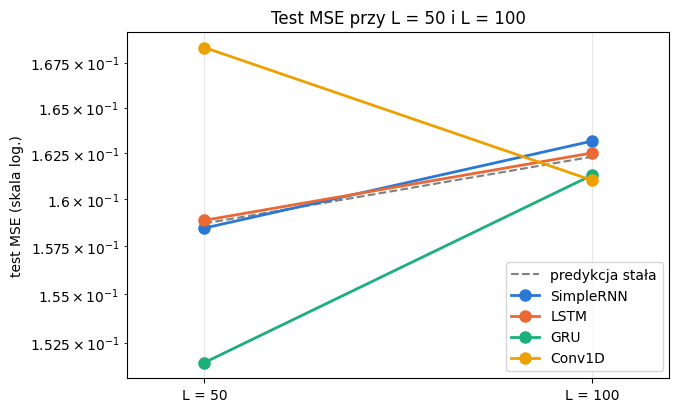

In [11]:
KOLORY = {'SimpleRNN': '#2a78d6', 'LSTM': '#eb6834', 'GRU': '#1baf7a', 'Conv1D': '#eda100'}
plt.figure(figsize=(7, 4.5))
plt.plot(DLUGOSCI, [dane[L]['mse_stala'] for L in DLUGOSCI], '--', color='gray',
         linewidth=1.5, label='predykcja stała')
for nazwa in BUDOWA:
    plt.plot(DLUGOSCI, [wyniki[(nazwa, L)]['mse'] for L in DLUGOSCI], 'o-',
             color=KOLORY[nazwa], linewidth=2, markersize=8, label=nazwa)
plt.yscale('log')
plt.xticks(DLUGOSCI, [f'L = {L}' for L in DLUGOSCI])
plt.xlim(40, 110)
plt.ylabel('test MSE (skala log.)')
plt.title('Test MSE przy L = 50 i L = 100')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 11. Przykład testowy z dużym błędem

In [12]:
L = 100
wybrany = min(BUDOWA, key=lambda n: wyniki[(n, L)]['mse'])
pred = wyniki[(wybrany, L)]['pred']
y = dane[L]['yte']
x = dane[L]['xte']
blad = np.abs(pred - y)
i = int(np.argmax(blad))

znaczniki = np.where(x[i, :, 1] == 1)[0] + 1
wskazane = znaczniki - OPOZNIENIE
wartosci = x[i, wskazane - 1, 0]
print(f'Model: {wybrany}, L={L}, test MSE={wyniki[(wybrany, L)]["mse"]:.4f}, '
      f'średni błąd bezwzględny={blad.mean():.4f}')
print(f'Przykład testowy nr {i}')
print('Znaczniki w krokach:', znaczniki.tolist(),
      '| kroków do końca sekwencji:', (L - znaczniki).tolist())
print('Wskazane kroki:', wskazane.tolist())
print('Wartości we wskazanych krokach:', [round(float(w), 4) for w in wartosci])
print(f'Prawidłowa suma: {y[i]:.4f}')
print(f'Predykcja: {pred[i]:.4f}')
print(f'Błąd bezwzględny: {blad[i]:.4f}')

Model: Conv1D, L=100, test MSE=0.1610, średni błąd bezwzględny=0.3286
Przykład testowy nr 600
Znaczniki w krokach: [52, 65] | kroków do końca sekwencji: [48, 35]
Wskazane kroki: [44, 57]
Wartości we wskazanych krokach: [0.9432, 0.9355]
Prawidłowa suma: 1.8787
Predykcja: 0.8797
Błąd bezwzględny: 0.9990
